# Capstone: Fading USD/INR shocks in GBP/INR
**Hypothesis:** after a large USD/INR move, GBP/INR moves in the same direction, then partly reverts over the next few days. Trade: fade the move in GBP/INR right after the shock.

Notebook stages (match the sections of the written report): 1 Data acquisition, 2 Cleaning, 3 Event study, 4 Strategy definition, 5 Backtest (train selection, test evaluation, robustness), 6 Efficiency and risk checks. Run *Kernel > Restart & Run All* before submitting. Data snapshot: `data/fx_raw.csv` (raw), `data/fx_clean.csv` (cleaned).

## 0. Setup and parameters

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

np.random.seed(42)
os.makedirs("data", exist_ok=True)

RAW_PATH = "data/fx_raw.csv"
START = "2010-01-01"
TICKERS = {"USDINR": "INR=X", "GBPINR": "GBPINR=X"}

PRE_WINDOW = 30          # pre-event level = MEAN of the previous 30 closes (event day excluded)
VOL_WINDOW = 252          # trading days used to measure "normal" USD/INR volatility
HORIZONS = [4, 5, 6, 7, 8]   # holding periods tested (trading days)
K_GRID = [1.5, 2.0, 2.5, 3.0]  # shock size = K * rolling std of USD/INR daily return
COOLDOWN = max(HORIZONS)  # min gap between events so trades never overlap
COST_BPS = 10             # base-case ROUND-TRIP cost in bps (see methodology defense)
SPLIT = "2020-01-01"      # train: before this date, test: from this date

## 1. Data acquisition

In [2]:
# Download once, save a snapshot to data/ and reuse it afterwards (so results are reproducible
# and the snapshot can be submitted with the notebook).
if os.path.exists(RAW_PATH):
    raw = pd.read_csv(RAW_PATH, index_col=0, parse_dates=True)
    print("Loaded snapshot from", RAW_PATH)
else:
    d = yf.download(list(TICKERS.values()), start=START, auto_adjust=True, progress=False)["Close"]
    inv = {v: k for k, v in TICKERS.items()}
    raw = d.rename(columns=inv)[list(TICKERS)]
    raw.to_csv(RAW_PATH)
    print("Downloaded and saved snapshot to", RAW_PATH)

raw = raw[list(TICKERS)]   # keep only the series used
print(raw.shape, raw.index.min().date(), "->", raw.index.max().date())
raw.tail()

Loaded snapshot from data/fx_raw.csv
(4369, 2) 2010-01-01 -> 2026-10-12


,USDINR,GBPINR
Date,,
2026-10-06,96.342796,127.352699
2026-10-07,96.370399,127.906235
2026-10-08,96.756798,127.527763
2026-10-09,96.823303,127.967148
2026-10-12,95.760002,126.737297


## 2. Cleaning

In [3]:
px = raw.sort_index()
px = px[~px.index.duplicated(keep="first")]

print("Missing values per series:\n", px.isna().sum(), "\n")

# Need both series on the same day.
n0 = len(px)
px = px.where(px > 0).dropna(how="any")
print(f"Dropped {n0 - len(px)} rows with a missing or non-positive price")

# Flag (but do not delete) very large single-day moves so they can be inspected.
big = px.pct_change().abs() > 0.05
print("\nDays with a >5% single-day move, per series:\n", big.sum())
# FX has no splits/dividends, so no corporate-action adjustment is needed.

px.to_csv("data/fx_clean.csv")
px.tail()

Missing values per series:
 USDINR    2
GBPINR    1
dtype: int64 

Dropped 3 rows with a missing or non-positive price

Days with a >5% single-day move, per series:
 USDINR    3
GBPINR    1
dtype: int64


,USDINR,GBPINR
Date,,
2026-10-06,96.342796,127.352699
2026-10-07,96.370399,127.906235
2026-10-08,96.756798,127.527763
2026-10-09,96.823303,127.967148
2026-10-12,95.760002,126.737297


In [ ]:
# Inspect the flagged days instead of only counting them: a one-day spike that reverses the next day
# is more likely a bad data tick than a real shock, and would look like a "reversion" to the strategy.
ret = px.pct_change()
flag = ret[(ret.abs() > 0.05).any(axis=1)]
ctx = pd.concat({"ret_today": flag, "ret_next_day": ret.shift(-1).loc[flag.index]}, axis=1)
print((ctx * 100).round(2).to_string())

## 3. Event definition and event study

In [4]:
def make_events(px, k, cooldown=COOLDOWN, vol_window=VOL_WINDOW):
    """Event on day t if |USDINR return_t| > k * (rolling std of USDINR returns up to t-1)
    AND GBPINR moved in the same direction on day t. Events are de-clustered."""
    r = px.pct_change()
    sigma = r["USDINR"].rolling(vol_window, min_periods=vol_window).std().shift(1)  # shift(1) = no look-ahead
    big = r["USDINR"].abs() > k * sigma
    same = np.sign(r["GBPINR"]) == np.sign(r["USDINR"])
    cand = (big & same).values

    keep, last = [], -10**9
    for i, flag in enumerate(cand):
        if flag and i - last > cooldown:
            keep.append(i)
            last = i
    ev = pd.Series(False, index=px.index)
    ev.iloc[keep] = True
    return ev


def event_table(px, ev, horizons=HORIZONS, pre_window=PRE_WINDOW):
    p = px["GBPINR"].values
    i = np.flatnonzero(ev.values)
    i = i[i >= pre_window]
    t = pd.DataFrame(index=px.index[i])
    # Pre-event level = mean of the `pre_window` closes BEFORE the event day (p[j-N:j] excludes day j)
    t["GBPINR_PreEvent"] = [p[j - pre_window : j].mean() for j in i]
    t["GBPINR"] = p[i]
    t["GBPINR_Move"] = t["GBPINR"] - t["GBPINR_PreEvent"]
    t["GBPINR_Return"] = t["GBPINR"] / t["GBPINR_PreEvent"] - 1
    t["Distance_Initial"] = t["GBPINR_Return"].abs()
    for h in horizons:
        fut = np.full(len(i), np.nan)
        ok = i + h < len(p)
        fut[ok] = p[i[ok] + h]
        t[f"GBPINR_Future_{h}"] = fut
        t[f"GBPINR_Future_Return_{h}"] = fut / t["GBPINR"] - 1
        # 1.0 = back at the pre-event mean, 0 = no reversion, <0 = move extended
        t[f"Reversal_Fraction_{h}"] = (t["GBPINR"] - fut) / t["GBPINR_Move"]
        t[f"Distance_{h}"] = (fut / t["GBPINR_PreEvent"] - 1).abs()
    return t


K_DEMO = 2.0
ev_demo = make_events(px, K_DEMO)
same_direction_events = event_table(px, ev_demo)
print(f"{len(same_direction_events)} de-clustered events at k={K_DEMO}\n")

rev_cols = [f"Reversal_Fraction_{h}" for h in HORIZONS]
print("Median reversal fraction (1.0 = fully back to the pre-event mean):")
print(same_direction_events[rev_cols].median(), "\n")

dist_cols = ["Distance_Initial"] + [f"Distance_{h}" for h in HORIZONS]
print("Median absolute distance from the pre-event mean:")
print(same_direction_events[dist_cols].median())

112 de-clustered events at k=2.0

Median reversal fraction (1.0 = fully back to the pre-event mean):
Reversal_Fraction_4    0.011311
Reversal_Fraction_5    0.052745
Reversal_Fraction_6    0.011382
Reversal_Fraction_7    0.059459
Reversal_Fraction_8    0.250857
dtype: float64 

Median absolute distance from the pre-event mean:
Distance_Initial    0.013166
Distance_4          0.016707
Distance_5          0.016597
Distance_6          0.017212
Distance_7          0.016901
Distance_8          0.015230
dtype: float64


In [5]:
# BASELINE: is reversion after events any different from reversion after ANY day?
# Measure = average "contrarian" gross return: -sign(today's USDINR move) * (GBPINR return over next h days).
r_all = px.pct_change()
rows = []
for h in HORIZONS:
    fut = px["GBPINR"].shift(-h) / px["GBPINR"] - 1
    contra = -np.sign(r_all["USDINR"]) * fut
    ev_mask = ev_demo
    a, b = contra[ev_mask].dropna(), contra[~ev_mask].dropna()
    se = a.std() / np.sqrt(len(a)) if len(a) > 1 else np.nan
    rows.append({"h": h, "events_n": len(a), "event_mean_bps": a.mean() * 1e4,
                 "event_t": a.mean() / se if se else np.nan,
                 "all_other_days_mean_bps": b.mean() * 1e4}) #This converts a decimal return into basis points (bps). 1%=100bps
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("\nIf event_mean_bps is not clearly above all_other_days_mean_bps, there is no special reversion after shocks.")

 h  events_n  event_mean_bps  event_t  all_other_days_mean_bps
 4       111            4.76     0.30                     1.47
 5       111           -8.66    -0.54                     0.64
 6       111           -3.57    -0.21                     0.85
 7       111           -5.67    -0.31                     0.68
 8       111            2.98     0.15                     1.54

If event_mean_bps is not clearly above all_other_days_mean_bps, there is no special reversion after shocks.


All t-stats are below 0.6, where you’d need about 2. The sign flips from one horizon to the next, which is what noise looks like. Shock days are statistically no different from ordinary days. This is the most important table, and it says there’s no effect.

## 4. Strategy definition
Fade rule: at the close of an event day, take the opposite side of the USD/INR shock in GBP/INR, hold H days, exit at the close of day t+H, one position at a time.

In [6]:
def backtest(px, k, H, cost_bps=COST_BPS, asset="GBPINR", cooldown=COOLDOWN):
    """At the close of event day t, take the OPPOSITE side of the USDINR shock in `asset`,
    hold for H trading days, exit at the close of t+H. Full notional, one position at a time.
    Cost is charged half on entry and half on exit (cost_bps is round trip)."""
    ev = make_events(px, k, cooldown)
    p = px[asset]
    r_asset = p.pct_change()
    r_usd = px["USDINR"].pct_change()
    n = len(px)
    pos = np.zeros(n)
    cost = np.zeros(n)
    trades = []
    for i in np.flatnonzero(ev.values):
        if i + H >= n:
            continue
        side = -np.sign(r_usd.iloc[i])
        pos[i + 1 : i + H + 1] = side
        cost[i + 1] += cost_bps / 2 / 1e4
        cost[i + H] += cost_bps / 2 / 1e4
        gross = p.iloc[i + H] / p.iloc[i] - 1
        trades.append({"entry_date": px.index[i], "side": side,
                       "net_ret": side * gross - cost_bps / 1e4})

    # Build the daily return series ONCE, after all trades are placed
    # (this was previously indented inside the for-loop, rebuilding it for every event).
    daily = pd.Series(pos * r_asset.fillna(0).values - cost, index=px.index)

    # Check how often the strategy holds a position
    print("Share of days with a position:", (pos != 0).mean())
    print("Share of days with non-zero returns:", (daily != 0).mean())
    return daily, pd.DataFrame(trades)



def stats(daily):
    daily = daily.dropna()
    if daily.std() == 0 or len(daily) == 0:
        return {"cum_return": np.nan, "sharpe": np.nan, "max_drawdown": np.nan}
    eq = (1 + daily).cumprod()
    return {"cum_return": eq.iloc[-1] - 1,
            "sharpe": daily.mean() / daily.std() * np.sqrt(252),   # idle days count as 0 return; no risk-free/carry
            "max_drawdown": (eq / eq.cummax() - 1).min()}


def split(daily, trades):
    tr_d, te_d = daily[daily.index < SPLIT], daily[daily.index >= SPLIT]
    if len(trades):
        tr_t, te_t = trades[trades.entry_date < SPLIT], trades[trades.entry_date >= SPLIT]
    else:
        tr_t = te_t = trades
    return tr_d, te_d, tr_t, te_t

## 5. Backtest
Parameters are chosen on the **train** period only (before 2020-01-01); the chosen setting is then evaluated once on the **test** period (2020-01-01 onwards).

In [7]:
# PARAMETER SEARCH ON TRAIN ONLY. 20 combinations tried in total (4 thresholds x 5 horizons).
rows = []
for k in K_GRID:
    for H in HORIZONS:
        daily, trades = backtest(px, k, H)
        tr_d, te_d, tr_t, te_t = split(daily, trades)
        s = stats(tr_d)
        rows.append({"k": k, "H": H, "train_trades": len(tr_t), **{f"train_{a}": b for a, b in s.items()}})
grid = pd.DataFrame(rows)
print(grid.round(3).to_string(index=False))

eligible = grid[grid.train_trades >= 10]
best = eligible.loc[eligible.train_sharpe.idxmax()]
K_BEST, H_BEST = float(best.k), int(best.H)
print(f"\nSelected on TRAIN data only: k={K_BEST}, H={H_BEST}  (1 of {len(grid)} combinations tried)")

Share of days with a position: 0.17040769583142465
Share of days with non-zero returns: 0.17017865322950068
Share of days with a position: 0.21300961978928082
Share of days with non-zero returns: 0.21255153458543288
Share of days with a position: 0.25561154374713696
Share of days with non-zero returns: 0.2549244159413651
Share of days with a position: 0.29821346770499313
Share of days with non-zero returns: 0.29706825469537335
Share of days with a position: 0.3408153916628493
Share of days with non-zero returns: 0.3396701786532295
Share of days with a position: 0.1016949152542373
Share of days with non-zero returns: 0.10123683005038937
Share of days with a position: 0.1271186440677966
Share of days with non-zero returns: 0.12643151626202473
Share of days with a position: 0.15254237288135594
Share of days with non-zero returns: 0.1516262024736601
Share of days with a position: 0.17796610169491525
Share of days with non-zero returns: 0.17704993128721944
Share of days with a position: 0.2

Based on highest Sharpe ratio in the training data

Share of days with a position: 0.29821346770499313
Share of days with non-zero returns: 0.29706825469537335
KEY RESULTS  (k=1.5, H=7, round-trip cost=10 bps)
                      cum_return  sharpe  max_drawdown  n_trades  hit_rate  avg_trade_bps
In-sample (train)          0.353   0.457        -0.140       108     0.556         30.246
Out-of-sample (test)      -0.024  -0.029        -0.138        78     0.474         -1.435


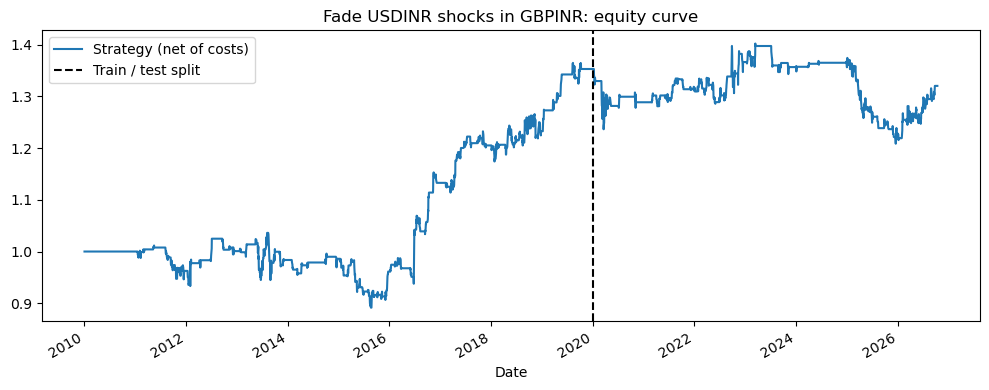

In [8]:
# FINAL RESULTS with the chosen parameters
daily, trades = backtest(px, K_BEST, H_BEST)
tr_d, te_d, tr_t, te_t = split(daily, trades)

res = pd.DataFrame({"In-sample (train)": stats(tr_d), "Out-of-sample (test)": stats(te_d)}).T
res["n_trades"] = [len(tr_t), len(te_t)]
res["hit_rate"] = [(tr_t.net_ret > 0).mean() if len(tr_t) else np.nan,
                   (te_t.net_ret > 0).mean() if len(te_t) else np.nan]
res["avg_trade_bps"] = [tr_t.net_ret.mean() * 1e4 if len(tr_t) else np.nan,
                        te_t.net_ret.mean() * 1e4 if len(te_t) else np.nan]
print(f"KEY RESULTS  (k={K_BEST}, H={H_BEST}, round-trip cost={COST_BPS} bps)")
print(res.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
(1 + daily).cumprod().plot(ax=ax, label="Strategy (net of costs)")
ax.axvline(pd.Timestamp(SPLIT), color="k", ls="--", label="Train / test split")
ax.set_title("Fade USDINR shocks in GBPINR: equity curve"); ax.legend(); plt.tight_layout()
plt.savefig("data/equity_curve.png", dpi=120); plt.show()

In [9]:
# Is the out-of-sample edge distinguishable from zero? Bootstrap the per-trade net return.
def bootstrap_mean(x, B=10000):
    x = np.asarray(x)
    if len(x) < 5:
        return np.nan, np.nan, np.nan
    means = np.random.choice(x, size=(B, len(x)), replace=True).mean(axis=1)
    return x.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)

for name, t in [("train", tr_t), ("test", te_t)]:
    m, lo, hi = bootstrap_mean(t.net_ret.values if len(t) else [])
    print(f"{name}: mean net return per trade = {m*1e4:.1f} bps, 95% CI [{lo*1e4:.1f}, {hi*1e4:.1f}] bps, n={len(t)}")
if len(te_t) < 30:
    print("\nWARNING: fewer than 30 test trades, so any conclusion is statistically weak.")

train: mean net return per trade = 30.2 bps, 95% CI [-9.0, 71.2] bps, n=108
test: mean net return per trade = -1.4 bps, 95% CI [-30.9, 28.5] bps, n=78


In [10]:
# TRANSACTION COST SENSITIVITY (same chosen k, H)
rows = []
for c in [0, 5, 10, 20, 30]:
    d, t = backtest(px, K_BEST, H_BEST, cost_bps=c)
    _, te_d_c, _, te_t_c = split(d, t)
    s = stats(te_d_c)
    rows.append({"round_trip_cost_bps": c, "test_cum_return": s["cum_return"],
                 "test_sharpe": s["sharpe"], "test_avg_trade_bps": te_t_c.net_ret.mean() * 1e4 if len(te_t_c) else np.nan})
print(pd.DataFrame(rows).round(3).to_string(index=False))

Share of days with a position: 0.29821346770499313
Share of days with non-zero returns: 0.29706825469537335
Share of days with a position: 0.29821346770499313
Share of days with non-zero returns: 0.29706825469537335
Share of days with a position: 0.29821346770499313
Share of days with non-zero returns: 0.29706825469537335
Share of days with a position: 0.29821346770499313
Share of days with non-zero returns: 0.29706825469537335
Share of days with a position: 0.29821346770499313
Share of days with non-zero returns: 0.29706825469537335
 round_trip_cost_bps  test_cum_return  test_sharpe  test_avg_trade_bps
                   0            0.055        0.159               8.565
                   5            0.015        0.065               3.565
                  10           -0.024       -0.029              -1.435
                  20           -0.097       -0.217             -11.435
                  30           -0.165       -0.404             -21.435


In [11]:
# ROBUSTNESS 1: all grid combinations on the TEST period (for transparency, NOT used to pick parameters)
rows = []
for k in K_GRID:
    for H in HORIZONS:
        d, t = backtest(px, k, H)
        _, te_d_g, _, te_t_g = split(d, t)
        rows.append({"k": k, "H": H, "test_trades": len(te_t_g), **{f"test_{a}": b for a, b in stats(te_d_g).items()}})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ROBUSTNESS 2: same signal, but trade USDINR directly instead of GBPINR
d_u, t_u = backtest(px, K_BEST, H_BEST, asset="USDINR")
_, te_u, _, te_tu = split(d_u, t_u)
print("\nTrading USDINR directly, test period:", {a: round(b, 3) for a, b in stats(te_u).items()}, "trades:", len(te_tu))

Share of days with a position: 0.17040769583142465
Share of days with non-zero returns: 0.17017865322950068
Share of days with a position: 0.21300961978928082
Share of days with non-zero returns: 0.21255153458543288
Share of days with a position: 0.25561154374713696
Share of days with non-zero returns: 0.2549244159413651
Share of days with a position: 0.29821346770499313
Share of days with non-zero returns: 0.29706825469537335
Share of days with a position: 0.3408153916628493
Share of days with non-zero returns: 0.3396701786532295
Share of days with a position: 0.1016949152542373
Share of days with non-zero returns: 0.10123683005038937
Share of days with a position: 0.1271186440677966
Share of days with non-zero returns: 0.12643151626202473
Share of days with a position: 0.15254237288135594
Share of days with non-zero returns: 0.1516262024736601
Share of days with a position: 0.17796610169491525
Share of days with non-zero returns: 0.17704993128721944
Share of days with a position: 0.2

## 6. Efficiency and risk checks

In [ ]:
# EFFICIENCY: time each stage separately instead of assuming which one is the bottleneck.
import time, io, contextlib

def timeit(f, reps=5):
    best = np.inf
    for _ in range(reps):
        t0 = time.perf_counter(); f(); best = min(best, time.perf_counter() - t0)
    return best

def silent(f):
    def g():
        with contextlib.redirect_stdout(io.StringIO()):
            return f()
    return g

r_usd_full = px["USDINR"].pct_change()
stages = {
    "rolling std (O(n))":                         lambda: r_usd_full.rolling(VOL_WINDOW, min_periods=VOL_WINDOW).std(),
    "event de-clustering loop (O(n), Python loop)": lambda: make_events(px, K_BEST),
    "ONE backtest (O(n + E*H))":                   silent(lambda: backtest(px, K_BEST, H_BEST)),
    "full 20-combination grid (G x one backtest)": silent(lambda: [backtest(px, k, H) for k in K_GRID for H in HORIZONS]),
    "bootstrap of test trades (O(B*m))":           lambda: bootstrap_mean(te_t.net_ret.values),
}
timing = pd.Series({name: timeit(f, reps=3) for name, f in stages.items()})
print(f"n = {len(px)} days | E = {int(make_events(px, K_BEST).sum())} events at k={K_BEST} | H = {H_BEST}\n")
print((timing * 1000).round(1).rename("milliseconds").to_string())
print("\nMost expensive single step:", timing.drop("full 20-combination grid (G x one backtest)").idxmax())
print("Most expensive overall:", timing.idxmax())


In [ ]:
# RISK: exposure, concentration and worst cases (uses `daily` and `trades` from the final-results cell)
inmkt = (daily != 0).mean()
print(f"\nShare of days in the market: {inmkt:.1%}  | exposure when in market: 1x notional, single pair")
print("Worst 5 trades:")
w = trades.sort_values("net_ret").head(5).copy()
w["net_ret_bps"] = (w.net_ret * 1e4).round(1)
print(w[["entry_date", "side", "net_ret_bps"]].to_string(index=False))
print(f"\nWorst single day: {daily.min()*1e4:.0f} bps | daily vol (ann.): {daily.std()*np.sqrt(252):.1%}")

Share of days in the market: 29.7%  | exposure when in market: 1x notional, single pair
Worst 5 trades:
entry_date  side  net_ret_bps
2013-08-13  -1.0       -555.7
2013-05-29  -1.0       -530.7
2015-04-21  -1.0       -417.5
2025-04-09  -1.0       -323.9
2018-11-08   1.0       -315.7

Worst single day: -478 bps | daily vol (ann.): 6.5%
